# Оптимизация модели kNN и отбор признаков (SBS)

**Цель работы:**
1. Обучить базовую модель kNN.
2. Реализовать алгоритм последовательного обратного выбора (SBS).
3. Ввести латентный признак и проанализировать изменение точности.

Импорт библиотек и загрузка данных

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Загрузка подготовленного датасета
df = pd.read_csv('ML-Dataset_cleaned.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'ML-Dataset_cleaned.csv'

Создание латентного признака и предобработка

In [46]:
cols_to_fix = ['Profit', 'OrderItemQuantity', 'ProductListPrice', 'ProductStandardCost', 'CustomerCreditLimit', 'TotalItemQuantity']
for col in cols_to_fix:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# латентные признаки
df['Profit_Per_Unit'] = df['Profit'] / (df['OrderItemQuantity'] + 1)
df['Profit_Margin'] = np.where(df['ProductListPrice'] != 0, df['Profit'] / df['ProductListPrice'], 0)

le = LabelEncoder()
y = le.fit_transform(df['CategoryName'].astype(str))

df['Status_Code'] = le.fit_transform(df['Status'].astype(str))
df['Job_Code'] = le.fit_transform(df['EmployeeJobTitle'].astype(str))

#  список признаков
features_list = [
    'ProductStandardCost', 'Profit', 'ProductListPrice',
    'CustomerCreditLimit', 'OrderItemQuantity', 'TotalItemQuantity',
    'Profit_Per_Unit', 'Status_Code', 'Job_Code', 'Profit_Margin'
]

# очистка и подготовка
X = df[features_list].copy().astype(float).fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

print(f"Используемые признаки: {len(features_list)}")
print(features_list)

Используемые признаки: 10
['ProductStandardCost', 'Profit', 'ProductListPrice', 'CustomerCreditLimit', 'OrderItemQuantity', 'TotalItemQuantity', 'Profit_Per_Unit', 'Status_Code', 'Job_Code', 'Profit_Margin']


Обучение базовой модели kNN

In [50]:
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_std, y_train)

y_pred_all = knn.predict(X_test_std)
accuracy_all = accuracy_score(y_test, y_pred_all)

descriptions = {
    'ProductStandardCost': 'Стоимость производства товара',
    'Profit':              'Общая прибыль по позиции',
    'ProductListPrice':    'Розничная прайсовая цена',
    'CustomerCreditLimit': 'Кредитный лимит покупателя',
    'OrderItemQuantity':   'Количество штук в заказе',
    'TotalItemQuantity':   'Общий объем товаров клиента',
    'Profit_Per_Unit':     'Прибыль на единицу (рассчитанный)',
    'Status_Code':         'Статус заказа (закодирован)',
    'Job_Code':            'Профессия сотрудника (закодирован)',
    'Profit_Margin':       'Маржинальность/Эффективность',
}
print(f"KNN на {len(features_list)} признаках")
for i, feature in enumerate(features_list, 1):
    desc = descriptions.get(feature, "Дополнительный параметр")
    print(f"{i:2}. {feature:20} | {desc}")
print(f"ИТОГОВАЯ ТОЧНОСТЬ: {accuracy_all:.2%}")


KNN на 10 признаках
 1. ProductStandardCost  | Стоимость производства товара
 2. Profit               | Общая прибыль по позиции
 3. ProductListPrice     | Розничная прайсовая цена
 4. CustomerCreditLimit  | Кредитный лимит покупателя
 5. OrderItemQuantity    | Количество штук в заказе
 6. TotalItemQuantity    | Общий объем товаров клиента
 7. Profit_Per_Unit      | Прибыль на единицу (рассчитанный)
 8. Status_Code          | Статус заказа (закодирован)
 9. Job_Code             | Профессия сотрудника (закодирован)
10. Profit_Margin        | Маржинальность/Эффективность
ИТОГОВАЯ ТОЧНОСТЬ: 63.33%


Реализация алгоритма SBS

In [51]:

def sbs_algorithm_detailed(X_train, X_test, y_train, y_test, model, feature_names):
    #  набор индексов признаков
    current_features = list(range(X_train.shape[1]))
    history = []

    # оценк точности на полном наборе данных
    model.fit(X_train, y_train)
    initial_score = accuracy_score(y_test, model.predict(X_test))
    history.append((len(current_features), initial_score, "None", tuple(current_features)))
    print(f"{'Осталось':<10} | {'Удален признак':<25} | {'Accuracy':<10}")
    print(f"{len(current_features):<10} | {'---':<25} | {initial_score:.4f}")

    while len(current_features) > 1:
        best_score = -1
        feature_to_remove_idx = -1
        for f in current_features:
            subset = [idx for idx in current_features if idx != f]
            # обучаем модель
            model.fit(X_train[:, subset], y_train)
            score = accuracy_score(y_test, model.predict(X_test[:, subset]))
            if score >= best_score:
                best_score = score
                feature_to_remove_idx = f
        removed_name = feature_names[feature_to_remove_idx]
        current_features.remove(feature_to_remove_idx)
        history.append((len(current_features), best_score, removed_name, tuple(current_features)))
        print(f"{len(current_features):<10} | {removed_name:<25} | {best_score:.4f}")
    return history

knn_optimized = KNeighborsClassifier(n_neighbors=5)

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

sbs_history = sbs_algorithm_detailed(X_train_std, X_test_std, y_train, y_test, knn_optimized, features_list)

Осталось   | Удален признак            | Accuracy  
10         | ---                       | 0.6333
9          | OrderItemQuantity         | 0.6917
8          | Status_Code               | 0.7500
7          | Profit_Margin             | 0.8000
6          | Profit_Per_Unit           | 0.8083
5          | CustomerCreditLimit       | 0.8750
4          | ProductListPrice          | 0.8667
3          | Profit                    | 0.8500
2          | Job_Code                  | 0.8083
1          | TotalItemQuantity         | 0.6167


Визуализация результатов

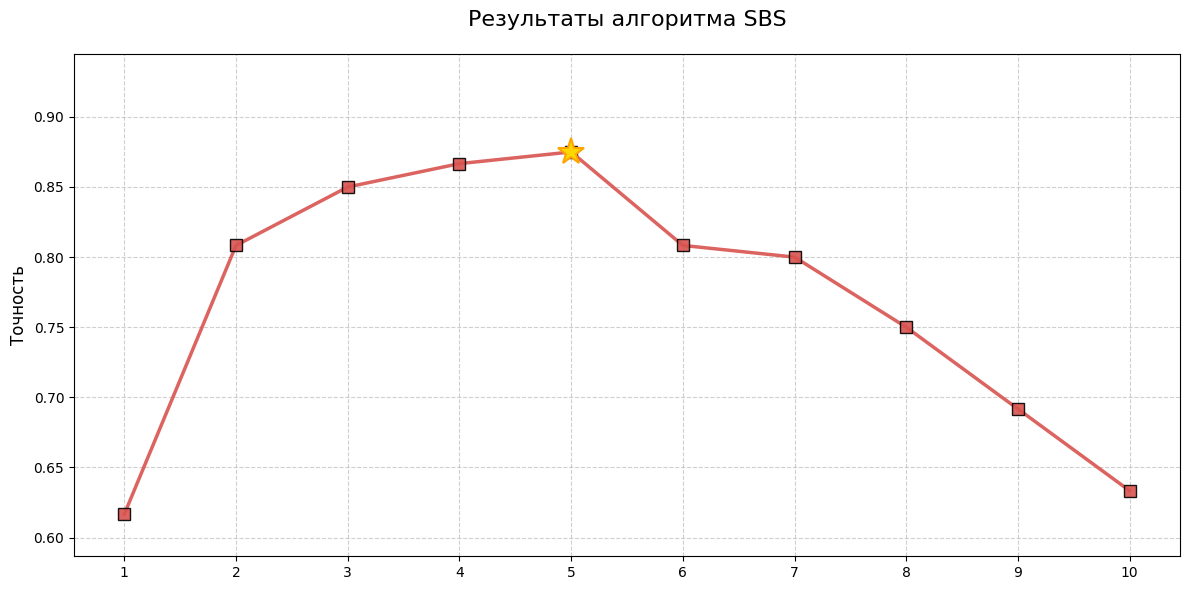

Результаты SBS:
- Исходная точность (10 признаков): 0.6333
- Максимальная точность:            0.8750 (при 5 признаках)
- Прирост за счет отбора:           0.2417


In [52]:
import matplotlib.pyplot as plt
import numpy as np

# подготовка данных из списка sbs_history
# sbs_history содержит (кол-во, точность, имя_удаленного, индексы)
sbs_raw_x = np.array([item[0] for item in sbs_history], dtype=int)
sbs_raw_y = np.array([item[1] for item in sbs_history], dtype=float)


sort_idx = np.argsort(sbs_raw_x)
sbs_x = sbs_raw_x[sort_idx]
sbs_y = sbs_raw_y[sort_idx]

max_acc = np.max(sbs_y)
best_n = sbs_x[np.argmax(sbs_y)]

plt.figure(figsize=(12, 6))

# график SBS
plt.plot(sbs_x, sbs_y, marker='s', label='SBS (Обратное исключение)', color='#d9534f', linewidth=2.5, markersize=9, linestyle='-', markeredgecolor='black', alpha=0.9)
plt.plot(best_n, max_acc, '*', color='gold', markersize=20, markeredgecolor='orange', markeredgewidth=1.5, zorder=5)
plt.title('Результаты алгоритма SBS', fontsize=16, pad=20)
plt.ylabel('Точность', fontsize=12)

# Сетка и оси
plt.xticks(range(1, 11))
plt.ylim(sbs_y.min() - 0.03, sbs_y.max() + 0.07)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Результаты SBS:")
print(f"- Исходная точность (10 признаков): {sbs_y[-1]:.4f}")
print(f"- Максимальная точность:            {max_acc:.4f} (при {best_n} признаках)")
print(f"- Прирост за счет отбора:           {max_acc - sbs_y[-1]:.4f}")